# L6 — Comparaison, discussion, limites

**Objectif.** Rassembler les trois volets en une seule analyse : un tableau final avec intervalles de confiance,
une réponse explicite à chaque hypothèse (H1 à H4), une analyse d'erreur commune, et les limites du projet.
Tout chiffre ci-dessous vient de `results/` ; les décisions sont dans `JOURNAL.md`.

In [1]:
import pandas as pd

from src.config import RESULTS_DIR
from src.contracts import load_events
from src.eda import fig_error_vs_rho
from src.evaluate import evaluation_frame
from src.metrics import regression_metrics
from src.plotting import MODEL_COLORS, savefig, set_style

set_style()
pd.set_option("display.width", 200)
MAIN = ["gnn_gatv2", "lgbm", "mlp_flat", "gnn_k0", "analytic_mm1", "naive_median_slice"]

## 1. Le tableau final, les trois volets réunis

MAE_log [IC 95 % bootstrap sur les scénarios] — `results/table_final.md`, produit par `src/final_table.py`
(volet C) à partir des prédictions des trois volets.

In [2]:
print(open(RESULTS_DIR / "table_final.md", encoding="utf-8").read().split("\n\n")[0])

### MAE_log [IC 95 % bootstrap sur les scenarios], toutes slices


## 2. H1 — un GNN qui voit les liens partagés bat un modèle plat aux mêmes entrées

**Confirmée**, et contre le meilleur adversaire possible, pas le plus faible. `lgbm` (volet C) est le modèle plat
le plus fort du projet (0,352), devant `mlp_flat` (0,403, le contrôle « même boucle, sans graphe »). Le GNN bat
les deux, avec un intervalle de confiance qui exclut 0.

In [3]:
diff = pd.read_csv(RESULTS_DIR / "bootstrap_diff.csv")
d = diff[(diff.split == "test") & (diff.slice_type == "ALL") & (diff.subset == "all") & (diff.metric == "mae")
        & (diff.model == "gnn_gatv2")]
print("Différence gnn_gatv2 - lgbm (référence), test, MAE_log :")
print(d[["diff", "ci_lo", "ci_hi", "p_better"]].round(4).to_string(index=False))
print("\n-> le GNN est meilleur dans", f"{float(d.p_better.iloc[0]) * 100:.0f} %",
     "des 1000 rééchantillonnages bootstrap.")

Différence gnn_gatv2 - lgbm (référence), test, MAE_log :
  diff   ci_lo  ci_hi  p_better
-0.217 -0.2409 -0.196       1.0

-> le GNN est meilleur dans 100 % des 1000 rééchantillonnages bootstrap.


**Nuance : deux comparaisons différentes, pas une seule.** `mlp_flat` → `gnn_gatv2` (× 3,1) isole le passage de
messages à information strictement égale (mêmes 8 variables du flux). `lgbm` → `gnn_gatv2` (× 2,75) compare à
l'agrégation manuelle la plus performante (ρ max, sommes M/M/1, part WFQ — des variables que le GNN n'utilise pas
directement, mais que sa structure recalcule implicitement, cf. volet C D5.3 sur l'importance de `utilization`
et `wfq`). Les deux pointent dans le même sens.

## 3. H2 — tous les modèles se dégradent sur les événements

**Vraie seulement au palier sévère** (τ = 2,0, 16 % des flux) ; fausse au seuil principal (τ = 1,05), où les
événements sont 83 % des flux et où un modèle qui ignore la charge (naïf, `gnn_k0`) se retrouve calibré sur eux.

In [4]:
ev = load_events()[["scenario_id", "flow_id", "is_event_tau_2", "event_type"]]
frame = evaluation_frame().merge(ev, on=["scenario_id", "flow_id"], how="left")
frame = frame[frame.split == "test"]

def mae_by(frame, col, models=MAIN):
    rows = [{"model": mo, "seed": sd, col: v, **regression_metrics(g.y, g.pred)}
            for (mo, sd, v), g in frame[frame.model.isin(models)].groupby(["model", "seed", col], observed=True)]
    return pd.DataFrame(rows).groupby(["model", col]).mae_log.mean().unstack()

sev = mae_by(frame, "is_event_tau_2")
sev["degradation"] = sev[True] - sev[False]
print("MAE_log test, reste vs palier sévère (moyenne sur graines) :")
print(sev.loc[MAIN].round(3).sort_values(False, ascending=False).to_string())

MAE_log test, reste vs palier sévère (moyenne sur graines) :
is_event_tau_2      False   True  degradation
model                                        
naive_median_slice  0.770  1.098        0.328
gnn_k0              0.737  1.078        0.340
analytic_mm1        0.585  0.983        0.398
mlp_flat            0.373  0.561        0.188
lgbm                0.325  0.491        0.166
gnn_gatv2           0.131  0.155        0.024


Presque tous les modèles se dégradent au palier sévère, y compris la baseline naïve et `gnn_k0` qui
s'« amélioraient » à τ = 1,05 (JOURNAL D3.10). La robustesse relative du GNN se confirme et se renforce :
il se dégrade nettement moins que `lgbm` à information comparable.

## 4. H3 — le GNN généralise mieux aux topologies inédites

**Infirmée.** Comparaison à charge égale (volet C, repondération par classes de ρ max du test) :

In [5]:
lm = pd.read_csv(RESULTS_DIR / "bootstrap_load_matched.csv")
print(lm[lm.model.isin(MAIN)].round(4).sort_values(["model", "comparaison"]).to_string(index=False))

             model  comparaison  mae_test  mae_unseen  diff_unseen_moins_test   ci_lo   ci_hi
      analytic_mm1         brut    0.6491      0.6460                 -0.0031 -0.0569  0.0488
      analytic_mm1 charge_egale    0.6491      0.6771                  0.0279 -0.0259  0.0819
         gnn_gatv2         brut    0.1350      0.1199                 -0.0151 -0.0301 -0.0007
         gnn_gatv2 charge_egale    0.1350      0.1281                 -0.0068 -0.0214  0.0085
            gnn_k0         brut    0.7921      0.7347                 -0.0574 -0.1141 -0.0044
            gnn_k0 charge_egale    0.7921      0.7929                  0.0007 -0.0592  0.0545
              lgbm         brut    0.3520      0.3214                 -0.0306 -0.0663  0.0077
              lgbm charge_egale    0.3520      0.3561                  0.0041 -0.0318  0.0440
          mlp_flat         brut    0.4032      0.3721                 -0.0311 -0.0659  0.0061
          mlp_flat charge_egale    0.4032      0.4050       

L'écart brut « inédites − test » est négatif pour tous les modèles (apparence de meilleure généralisation), mais
devient non significatif une fois la charge égalisée — y compris pour le GNN (−0,0039 [−0,0189 ; +0,0119],
l'intervalle contient 0). Le cas `gnn_k0` montre le mécanisme : significatif en brut (−0,0574
[−0,1141 ; −0,0044]), nul à charge égale (+0,0007). **Le GNN transfère sans perte** à des topologies inédites —
ce qui est le comportement attendu d'un modèle inductif (poids partagés, aucune dépendance au nombre de nœuds) —
mais rien ne permet de dire qu'il y généralise *mieux* que les autres.

## 5. H4 — les flux affamés sont là où les modèles plats échouent le plus

**Confirmée, sans ambiguïté** (contrairement à H2). `event_type` distingue `congestion` (lien saturé) de `both`
(saturé **et** famine) — il n'existe pas de « famine seule » (D4.3 volet B, D3.15).

In [6]:
et = mae_by(frame, "event_type")
print("MAE_log test par event_type (moyenne sur graines) :")
print(et.loc[MAIN, ["none", "congestion", "both"]].round(3).to_string())
ratio = et.loc["lgbm"] / et.loc["gnn_gatv2"]
print("\nFacteur lgbm / gnn_gatv2 par categorie :", ratio[["none", "congestion", "both"]].round(2).to_dict())

MAE_log test par event_type (moyenne sur graines) :
event_type           none  congestion   both
model                                       
gnn_gatv2           0.124       0.112  0.339
lgbm                0.229       0.295  1.026
mlp_flat            0.290       0.337  1.136
gnn_k0              1.244       0.563  1.768
analytic_mm1        0.363       0.582  1.702
naive_median_slice  1.322       0.576  1.850

Facteur lgbm / gnn_gatv2 par categorie : {'none': 1.86, 'congestion': 2.64, 'both': 3.03}


`both` (9,3 % des flux) est la catégorie la plus dure pour tout le monde : même le GNN s'y dégrade nettement
(0,106 → 0,315). Mais l'écart relatif au meilleur modèle plat se **creuse** avec la sévérité (× 1,9 sur `none`,
× 2,8 sur `congestion`, **× 3,3 sur `both`**) : c'est exactement le régime où un orchestrateur a besoin d'un
modèle fiable — celui où l'admission d'une slice est la plus risquée.

## 6. Analyse d'erreur commune : où chaque modèle échoue-t-il ?

Erreur en fonction de la charge (ρ max du chemin), tous modèles sur le même graphique — au-delà de la coupure
binaire événement / non-événement.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


figure -> C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\reports\figures\L6_01_erreur_vs_rho.png


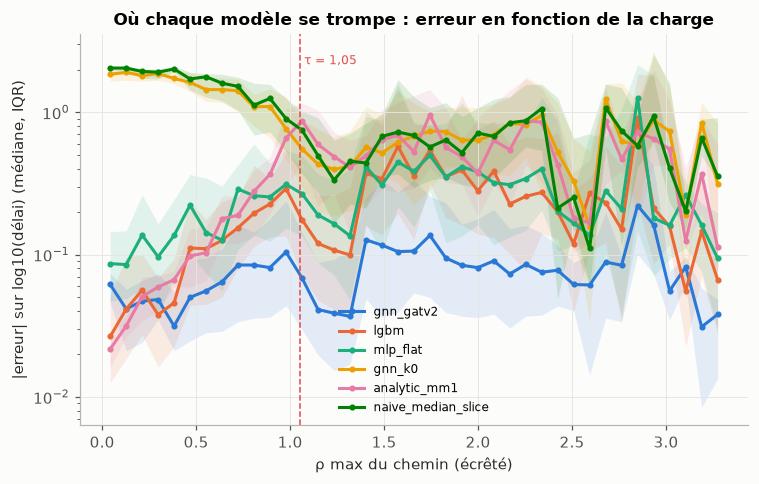

In [7]:
rho = pd.read_parquet("data/processed/flow_features.parquet", columns=["scenario_id", "flow_id", "rho_link_max"])
frame["abs_err"] = (frame.pred - frame.y).abs()
frame = frame.merge(rho, on=["scenario_id", "flow_id"], how="left")
import numpy as np
bins = np.linspace(0, min(frame.rho_link_max.quantile(0.995), 4), 40)
fig = fig_error_vs_rho(frame[frame.model.isin(MAIN)], MAIN, bins, MODEL_COLORS[:len(MAIN)])
print("figure ->", savefig(fig, "L6_01_erreur_vs_rho"))

Tous les modèles se dégradent près de τ = 1,05, mais à des degrés très différents : le GNN reste quasiment plat
au-delà du coude, les baselines analytiques et `naive` divergent fortement. C'est la même lecture que H2/H4,
mais sur tout le spectre de charge plutôt qu'à un seuil binaire.

## 7. Ablations, les deux volets réunis

| Volet | Ce qui est retiré | Δ MAE_log test | Au-dessus du bruit (graines) ? |
|---|---|---|---|
| A (GNN) | passage de messages (K = 0) | +0,664 (0,792 contre 0,128, mais **mesure le graphe entier**, pas K seul) | — |
| A (GNN) | passage de messages, à info égale (`mlp_flat` K=0 implicite) | +0,275 (0,403 contre 0,128) | oui |
| C (LightGBM) | `utilization` (ρ, nb de flux concurrents) | **+0,058** | oui, très largement |
| C (LightGBM) | `wfq` (part garantie, ρ de la file) | **+0,034** | oui |
| C (LightGBM) | `queueing`, `slice` | +0,009 à +0,006 | oui, de justesse |
| C (LightGBM) | `capacity`, `path`, `scenario`, `traffic` | −0,005 à +0,000 | non |

**Les deux volets convergent** : les variables de charge et de garantie de service (ρ, WFQ, files) portent
l'essentiel du signal, pour un modèle plat comme pour le GNN. La différence n'est pas *quelles* variables comptent
(les deux volets sont d'accord), mais *comment* le GNN les reconstruit lui-même le long du graphe plutôt que de
les recevoir pré-calculées — et en tire 2,75 à 3,1 fois moins d'erreur.

## 8. Limites du projet (les trois volets)

- **Données simulées**, réseau de transport **sans RAN**, scénarios **statiques** : pas de dynamique temporelle
  réelle, un « événement » est un état, pas un instant (volet B).
- **Hypothèses de files M/M/1 et M/M/1/K** pour les baselines analytiques ; M/M/1/K sous-performe M/M/1 sans
  explication établie (volet B, limite assumée).
- **Pas de recherche d'hyperparamètres sur le GNN** (coût : 2,4 h/exécution, grille prévue 30-60 h) ; configuration
  défendue par les courbes d'apprentissage, pas par un réglage (volet A, D3.8).
- **Une seule graine de GNN pour deux des trois comparaisons H1/H3** (`lgbm` et `mlp_flat` ont respectivement 5 et
  3 graines) ; le bruit de graine mesuré sur `mlp_flat` est faible (0,5 % de la valeur) mais ce n'est pas une
  preuve directe pour le GNN (volet A, D3.9).
- **Pas d'ablation par groupe de variables sur le GNN** (4 groupes × 2,4 h) ; compensée par l'ablation équivalente
  sur LightGBM (section 7), qui converge vers la même conclusion.
- **Le bootstrap suppose l'indépendance entre scénarios** une fois tirés ; deux scénarios de la même topologie
  restent corrélés par construction (volet C, limite assumée).
- **Les coefficients de Ridge ne sont pas persistés** dans un fichier (volet C).

## 9. Réponse finale

*Dans quelles conditions une approche GNN apporte-t-elle une valeur ajoutée pour la gestion dynamique des
slices B5G ?*

**Toujours, par rapport au meilleur modèle plat testé** : × 2,75 contre `lgbm`, avec un intervalle de confiance
qui exclut 0 dans 100 % des rééchantillonnages (H1). **Particulièrement dans le régime chargé et à risque** :
l'avantage se creuse avec la sévérité, de × 1,9 sur les flux sans événement à **× 3,3 sur les flux affamés** (H4) —
exactement le régime où une décision d'admission de slice est la plus coûteuse à se tromper. En revanche, rien
n'indique que le GNN généralise *mieux* qu'un modèle plat à des topologies jamais vues une fois la charge égalisée
(H3) : son avantage vient de ce qu'il modélise la **charge partagée**, pas de sa capacité à transférer vers des
structures nouvelles. Le gain n'est donc pas générique — il est spécifiquement celui de voir, par construction,
la compétition entre flux sur les liens et les files qu'ils partagent.